# Programming Sheet 1: Bayes Decision Theory

This warm-up sheet is not graded. We compute the quantities of Bayes decision theory numerically for small two-dimensional problems: densities, posteriors, decisions and error rates.

**Quiz.** Each exercise asks for one function (exercise 1 for three small ones). Submit them in the ISIS quiz for this sheet, which also contains a few short multiple-choice questions. The quiz checks your functions on several inputs and explains with figures what they compute.

In [1]:
import numpy as np
import matplotlib
%matplotlib inline
from matplotlib import pyplot as plt

# a grid of the square [-4, 4]^2 with step size 0.1
r = np.arange(-4, 4 + 1e-9, 0.1)
G1, G2 = np.meshgrid(r, r)                      # rows: x2, columns: x1
X = np.column_stack([G1.ravel(), G2.ravel()])   # the grid points as a dataset, shape (6561, 2)
cell_area = 0.1 * 0.1

def show(values, title, ax=None, **kwargs):
    # show values on the grid points (6561,) as an image, x1 to the right, x2 upwards
    ax = ax or plt.gca()
    ax.imshow(np.reshape(values, G1.shape), origin='lower', extent=(-4, 4, -4, 4), **kwargs)
    ax.set_xlabel('$x_1$')
    ax.set_ylabel('$x_2$')
    ax.set_title(title)

print(X.shape)

(6561, 2)


## Exercise 1: Probability Tables (warm-up)

Two discrete random variables $x_1$ and $x_2$ each take the 81 values in `r`. Their joint distribution is a table `P` of shape (81, 81) with entries $P[i, j] = P(x_1 = r_i, x_2 = r_j)$ that sum to 1.

* **Implement `normalize(F)`**, which returns the distribution $F / \sum_{i,j} F[i, j]$ proportional to a table `F` of non-negative numbers.
* **Implement `condition(P, event)`**, which returns $P(x_1, x_2 \mid \text{event})$ for a boolean table `event` (true where the event holds).
* **Implement `marginalize(P)`**, which returns the marginal distribution $P(x_1 = r_i) = \sum_j P[i, j]$, an array of shape (81,).

In [2]:
def normalize(F):

    ## -------------------------------
    ## TODO: replace by your solution
    ## -------------------------------
    import solutions
    P = solutions.normalize(F)
    ## -------------------------------

    return P

In [3]:
def condition(P, event):

    ## -------------------------------
    ## TODO: replace by your solution
    ## -------------------------------
    import solutions
    Q = solutions.condition(P, event)
    ## -------------------------------

    return Q

In [4]:
def marginalize(P):

    ## -------------------------------
    ## TODO: replace by your solution
    ## -------------------------------
    import solutions
    M = solutions.marginalize(P)
    ## -------------------------------

    return M

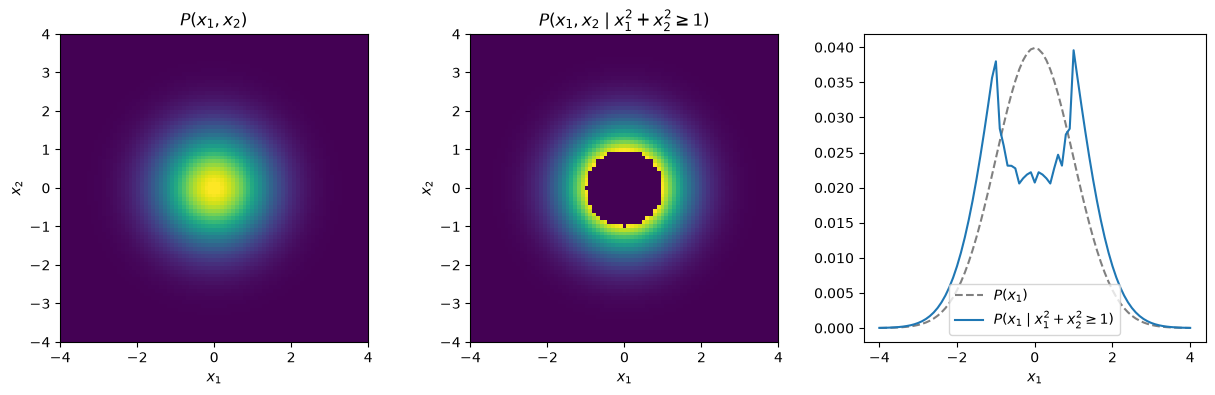

In [5]:
T1, T2 = np.meshgrid(r, r, indexing='ij')        # table axes: x1, x2
P = normalize(np.exp(-0.5 * (T1**2 + T2**2)))     # discretized standard normal distribution
Q = condition(P, T1**2 + T2**2 >= 1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, table, title in ((axes[0], P, '$P(x_1, x_2)$'), (axes[1], Q, '$P(x_1, x_2 \\mid x_1^2 + x_2^2 \\geq 1)$')):
    ax.imshow(table.T, origin='lower', extent=(-4, 4, -4, 4), vmax=Q.max())
    ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$'); ax.set_title(title)
axes[2].plot(r, marginalize(P), '--', color='0.5', label='$P(x_1)$')
axes[2].plot(r, marginalize(Q), label='$P(x_1 \\mid x_1^2 + x_2^2 \\geq 1)$')
axes[2].set_xlabel('$x_1$'); axes[2].legend()
plt.show()

## Exercise 2: The Multivariate Normal Density

A dataset is an array `X` of shape (N, d) whose rows are points $x$. The Gaussian density with mean $\mu$ and covariance $\Sigma$ is (for $d = 2$)

$$
p(x) = \frac{1}{2\pi \sqrt{\det \Sigma}} \exp\Big(-\frac12 (x-\mu)^\top \Sigma^{-1} (x-\mu)\Big).
$$

* **Implement `gaussian_density(X, mu, Sigma)`**, which returns $p(x)$ for every row of `X`, an array of shape (N,). Use array operations on all rows at once (`X - mu`, `@`). Careful: `(X - mu) @ A @ (X - mu).T` is an N × N matrix, of which you only need the diagonal.

In [6]:
def gaussian_density(X, mu, Sigma):

    ## -------------------------------
    ## TODO: replace by your solution
    ## -------------------------------
    import solutions
    p = solutions.gaussian_density(X, mu, Sigma)
    ## -------------------------------

    return p

sum x cell area: 1.0
sum x cell area: 1.0
sum x cell area: 0.983


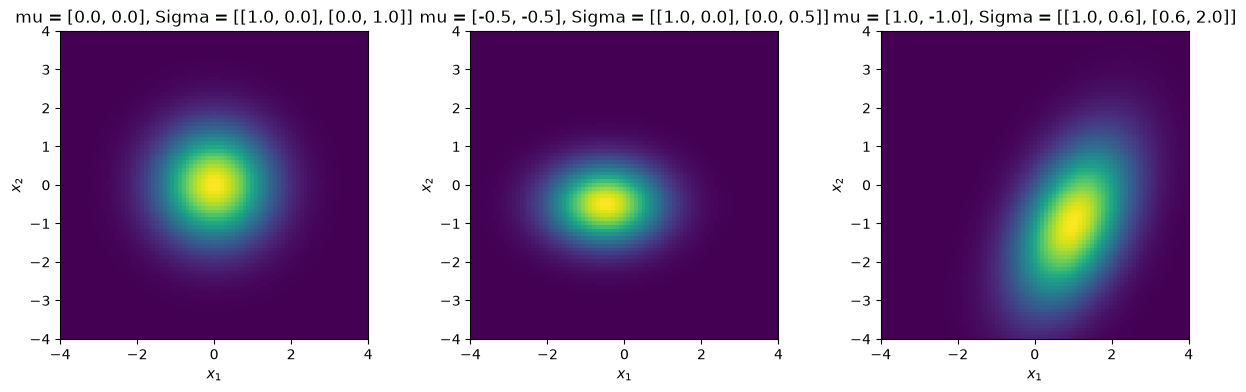

In [7]:
cases = [(np.zeros(2), np.eye(2)),
         (np.array([-0.5, -0.5]), np.array([[1.0, 0.0], [0.0, 0.5]])),
         (np.array([1.0, -1.0]), np.array([[1.0, 0.6], [0.6, 2.0]]))]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (mu, Sigma) in zip(axes, cases):
    p = gaussian_density(X, mu, Sigma)
    show(p, f'mu = {mu.tolist()}, Sigma = {Sigma.tolist()}', ax)
    print('sum x cell area:', round(p.sum() * cell_area, 3))
plt.show()

## Exercise 3: Bayes' Rule

A problem with $C$ classes is given by `likelihoods`, an array of shape (N, C) with entries $p(x_n \mid \omega_j)$, and `priors`, an array of shape (C,) with entries $P(\omega_j)$.

* **Implement `posteriors(likelihoods, priors)`**, which returns the posteriors $P(\omega_j \mid x_n) = p(x_n \mid \omega_j) P(\omega_j) / p(x_n)$ with $p(x_n) = \sum_k p(x_n \mid \omega_k) P(\omega_k)$, an array of shape (N, C).

We use two Gaussian classes with means $\mu_1 = (-0.5, -0.5)$, $\mu_2 = (0.5, 0.5)$ and the shared covariance $\Sigma = \operatorname{diag}(1, 0.5)$, with equal priors and with the priors 0.9 / 0.1.

In [8]:
def posteriors(likelihoods, priors):

    ## -------------------------------
    ## TODO: replace by your solution
    ## -------------------------------
    import solutions
    Q = solutions.posteriors(likelihoods, priors)
    ## -------------------------------

    return Q

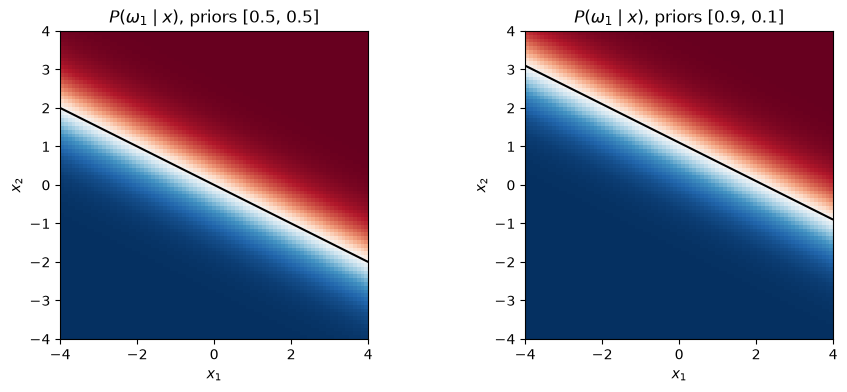

In [9]:
mu1, mu2 = np.array([-0.5, -0.5]), np.array([0.5, 0.5])
Sigma = np.array([[1.0, 0.0], [0.0, 0.5]])
L = np.column_stack([gaussian_density(X, mu1, Sigma), gaussian_density(X, mu2, Sigma)])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, priors in zip(axes, (np.array([0.5, 0.5]), np.array([0.9, 0.1]))):
    Q = posteriors(L, priors)
    show(Q[:, 0], f'$P(\\omega_1 \\mid x)$, priors {priors.tolist()}', ax, cmap='RdBu', vmin=0, vmax=1)
    ax.contour(G1, G2, np.reshape(Q[:, 0], G1.shape), levels=[0.5], colors='k')
plt.show()

## Exercise 4: The Bayes Error Rate

The optimal decision at $x$ is wrong with probability $P(\text{Err} \mid x) = 1 - \max_j P(\omega_j \mid x)$. The Bayes error rate averages this over $x$:

$$
P(\text{Err}) = \int P(\text{Err} \mid x)\, p(x)\, dx \;\approx\; \sum_n P(\text{Err} \mid x_n)\, p(x_n) \cdot \mathtt{cell\_area}.
$$

* **Implement `bayes_error(likelihoods, priors, cell_area)`**, which returns this approximation for points $x_n$ on a grid.

The plot compares the Bayes error for different priors with the error of ignoring $x$ and always predicting the more frequent class.

In [10]:
def bayes_error(likelihoods, priors, cell_area):

    ## -------------------------------
    ## TODO: replace by your solution
    ## -------------------------------
    import solutions
    error = solutions.bayes_error(likelihoods, priors, cell_area)
    ## -------------------------------

    return error

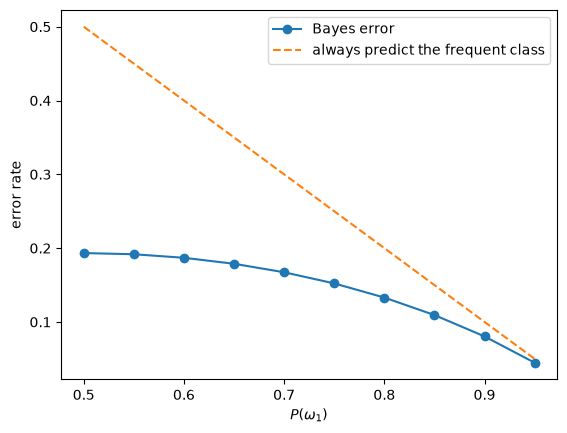

Bayes error for the priors 0.9 / 0.1: 0.080


In [11]:
p1 = np.linspace(0.5, 0.95, 10)
errors = [bayes_error(L, np.array([q, 1 - q]), cell_area) for q in p1]
plt.plot(p1, errors, 'o-', label='Bayes error')
plt.plot(p1, 1 - p1, '--', label='always predict the frequent class')
plt.xlabel('$P(\\omega_1)$'); plt.ylabel('error rate'); plt.legend()
plt.show()
print('Bayes error for the priors 0.9 / 0.1: %.3f' % bayes_error(L, np.array([0.9, 0.1]), cell_area))

## Exercise 5: The Linear Decision Boundary

For Gaussian classes with a shared covariance, the optimal decision is $\omega_1$ where $w^\top x + b > 0$, with

$$
w = \Sigma^{-1}(\mu_1 - \mu_2), \qquad
b = -\frac12 \mu_1^\top \Sigma^{-1} \mu_1 + \frac12 \mu_2^\top \Sigma^{-1} \mu_2 + \log \frac{P(\omega_1)}{P(\omega_2)}.
$$

* **Implement `linear_boundary(mu1, mu2, Sigma, prior1, prior2)`**, which returns the pair `(w, b)`.

The plot draws your line on top of the posterior of Exercise 3 (priors 0.9 / 0.1), together with the line between the means.

In [12]:
def linear_boundary(mu1, mu2, Sigma, prior1, prior2):

    ## -------------------------------
    ## TODO: replace by your solution
    ## -------------------------------
    import solutions
    w, b = solutions.linear_boundary(mu1, mu2, Sigma, prior1, prior2)
    ## -------------------------------

    return w, b

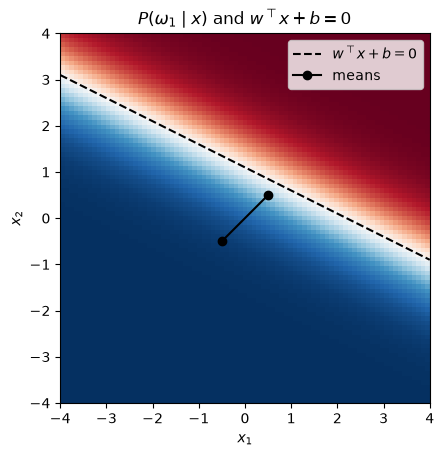

In [13]:
w, b = linear_boundary(mu1, mu2, Sigma, 0.9, 0.1)
show(posteriors(L, np.array([0.9, 0.1]))[:, 0], '$P(\\omega_1 \\mid x)$ and $w^\\top x + b = 0$',
     cmap='RdBu', vmin=0, vmax=1)
plt.plot(r, -(w[0] * r + b) / w[1], 'k--', label='$w^\\top x + b = 0$')
plt.plot(*np.array([mu1, mu2]).T, 'ko-', label='means')
plt.xlim(-4, 4); plt.ylim(-4, 4); plt.legend()
plt.show()

## Exercise 6: Gaussian Classes with Different Covariances

With different covariances $\Sigma_j$, the optimal decision compares the discriminant functions

$$
g_j(x) = -\frac12 (x - \mu_j)^\top \Sigma_j^{-1} (x - \mu_j) - \frac12 \log \det \Sigma_j + \log P(\omega_j).
$$

* **Implement `discriminant(X, mu, Sigma, prior)`**, which returns $g_j(x)$ for every row of `X`, an array of shape (N,).

We keep $\Sigma_1 = \Sigma$ and concentrate the second class around its mean, $\Sigma_2 = \Sigma / 4$, with the priors 0.9 / 0.1.

In [14]:
def discriminant(X, mu, Sigma, prior):

    ## -------------------------------
    ## TODO: replace by your solution
    ## -------------------------------
    import solutions
    g = solutions.discriminant(X, mu, Sigma, prior)
    ## -------------------------------

    return g

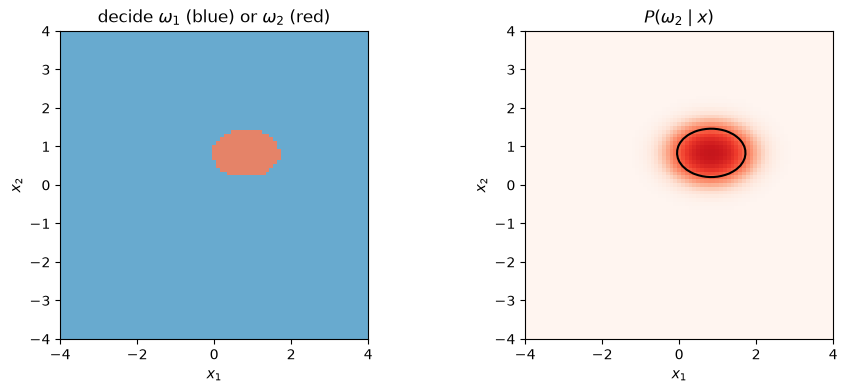

largest posterior of class 2: 0.766


In [15]:
D = discriminant(X, mu1, Sigma, 0.9) - discriminant(X, mu2, Sigma / 4, 0.1)
L4 = np.column_stack([gaussian_density(X, mu1, Sigma), gaussian_density(X, mu2, Sigma / 4)])
Q4 = posteriors(L4, np.array([0.9, 0.1]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
show(np.where(D > 0, 1.0, 0.0), 'decide $\\omega_1$ (blue) or $\\omega_2$ (red)', axes[0],
     cmap='RdBu', vmin=-0.5, vmax=1.5)
show(Q4[:, 1], '$P(\\omega_2 \\mid x)$', axes[1], cmap='Reds', vmin=0, vmax=1)
axes[1].contour(G1, G2, np.reshape(D, G1.shape), levels=[0], colors='k')
plt.show()
print('largest posterior of class 2: %.3f' % Q4[:, 1].max())

**Question.** With a shared covariance (Exercise 3), the posterior $P(\omega_2 \mid x)$ comes close to 1 far away on the side of $\omega_2$. Concentrating the data of class 2 in a smaller region should make it even easier to predict class 2 with certainty there. Yet now $P(\omega_2 \mid x)$ does not reach 1 anywhere. Why? (One of the multiple-choice questions of the quiz asks about this.)